In [1]:
pip install opencv-python numpy dlib

Розмір початкового зображення (Висота, Ширина, Канали): (480, 512, 3)


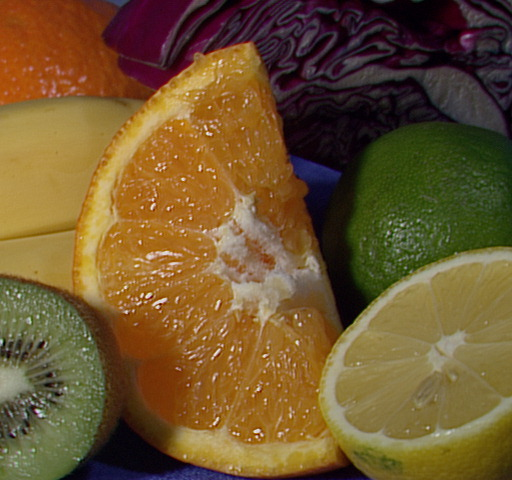

In [2]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import urllib.request

url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg"
urllib.request.urlretrieve(url, "input_image.jpg")

image = cv2.imread("input_image.jpg", cv2.IMREAD_COLOR)
print(f"Розмір початкового зображення (Висота, Ширина, Канали): {image.shape}")
cv2_imshow(image)

=== 1. Результат кадрування ===


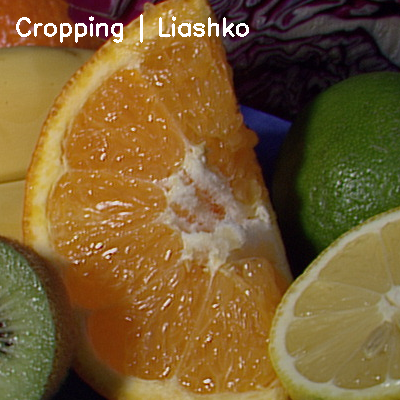

True

In [3]:
cropped_img = image[50:450, 50:450].copy()

crop_labeled = cropped_img.copy()
cv2.putText(crop_labeled, "Cropping | Liashko", (15, 35),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)

print("=== 1. Результат кадрування ===")
cv2_imshow(crop_labeled)
cv2.imwrite("result_1_crop.jpg", crop_labeled)



Експеримент 1 (EXT | Thr:100 | SIMPLE):
 -> Знайдено контурів: 74, всього збережено точок: 1748


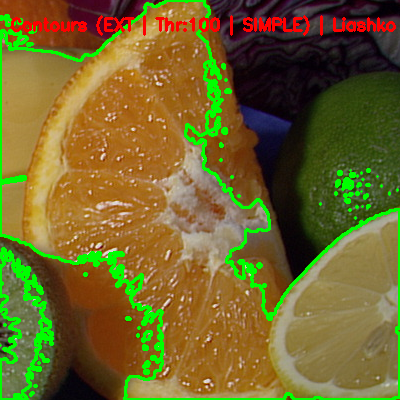


Експеримент 2 (TREE | Thr:100 | NONE):
 -> Знайдено контурів: 191, всього збережено точок: 5205


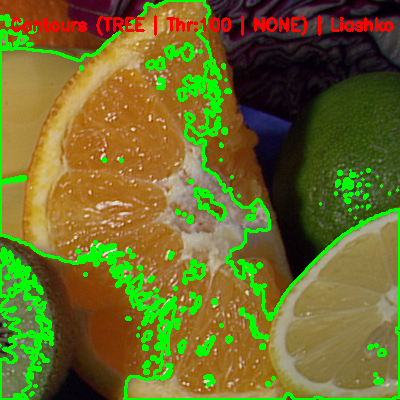


Експеримент 3 (TREE | Thr:160 | SIMPLE):
 -> Знайдено контурів: 107, всього збережено точок: 1226


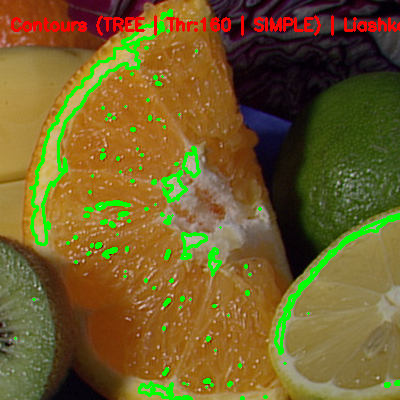

In [4]:
gray = cv2.cvtColor(cropped_img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

configs = [
    {"thr": 100, "mode": cv2.RETR_EXTERNAL, "method": cv2.CHAIN_APPROX_SIMPLE, "name": "EXT | Thr:100 | SIMPLE"},
    {"thr": 100, "mode": cv2.RETR_TREE,     "method": cv2.CHAIN_APPROX_NONE,   "name": "TREE | Thr:100 | NONE"},
    {"thr": 160, "mode": cv2.RETR_TREE,     "method": cv2.CHAIN_APPROX_SIMPLE, "name": "TREE | Thr:160 | SIMPLE"}
]

for idx, cfg in enumerate(configs, 1):
    _, binary = cv2.threshold(blurred, cfg["thr"], 255, cv2.THRESH_BINARY)

    contours, hierarchy = cv2.findContours(binary, cfg["mode"], cfg["method"])

    total_points = sum(len(c) for c in contours)
    print(f"\nЕксперимент {idx} ({cfg['name']}):")
    print(f" -> Знайдено контурів: {len(contours)}, всього збережено точок: {total_points}")

    contour_img = cropped_img.copy()
    cv2.drawContours(contour_img, contours, -1, (0, 255, 0), 2)

    label = f"Contours ({cfg['name']}) | Liashko"
    cv2.putText(contour_img, label, (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2)

    cv2_imshow(contour_img)
    cv2.imwrite(f"result_2_contours_exp{idx}.jpg", contour_img)

In [5]:
import os
import bz2
import urllib.request
import dlib

model_bz2 = "shape_predictor_68_face_landmarks.dat.bz2"
model_dat = "shape_predictor_68_face_landmarks.dat"

if not os.path.exists(model_dat):
    print("Завантаження моделі shape_predictor_68_face_landmarks.dat...")
    url_model = "http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2"
    urllib.request.urlretrieve(url_model, model_bz2)

    print("Розпакування архіву...")
    with bz2.BZ2File(model_bz2) as fr, open(model_dat, "wb") as fw:
        fw.write(fr.read())
    print("Модель успішно підготовлена!")
else:
    print("Модель вже завантажена.")

Завантаження моделі shape_predictor_68_face_landmarks.dat...
Розпакування архіву...
Модель успішно підготовлена!


In [9]:
# Завантажуємо базове портретне зображення однієї людини
face_url = "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama.jpg"
urllib.request.urlretrieve(face_url, "face_base.jpg")
base_face = cv2.imread("face_base.jpg")

# Зменшимо до зручного розміру для наочності
base_face = cv2.resize(base_face, (500, 600))

In [10]:
# Моделюємо 4 різні умови зйомки однієї і тієї ж людини:
# 1. Нормальні умови (оригінал)
cond_normal = base_face.copy()

In [11]:
# 2. Слабке освітлення (недоекспозиція, темне приміщення)
cond_dark = cv2.convertScaleAbs(base_face, alpha=0.25, beta=-20)

In [12]:
# 3. Засвічене фото (переекспозиція / яскраве зустрічне світло)
cond_bright = cv2.convertScaleAbs(base_face, alpha=1.6, beta=70)

In [13]:
# 4. Складні умови: нахил камери (поворот на 35 градусів) + розмиття в русі
center = (base_face.shape[1] // 2, base_face.shape[0] // 2)
rot_matrix = cv2.getRotationMatrix2D(center, 35, 1.0)
cond_rotated = cv2.warpAffine(base_face, rot_matrix, (base_face.shape[1], base_face.shape[0]))
cond_rotated = cv2.GaussianBlur(cond_rotated, (7, 7), 0)


Умова 1 (Normal Light): знайдено облич — 1


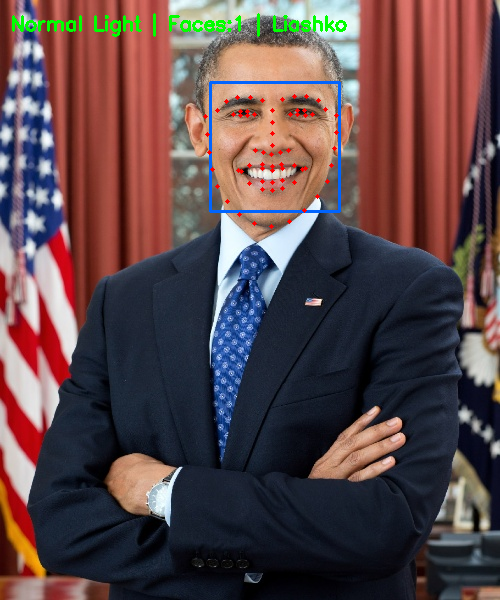


Умова 2 (Low Light (Dark)): знайдено облич — 1


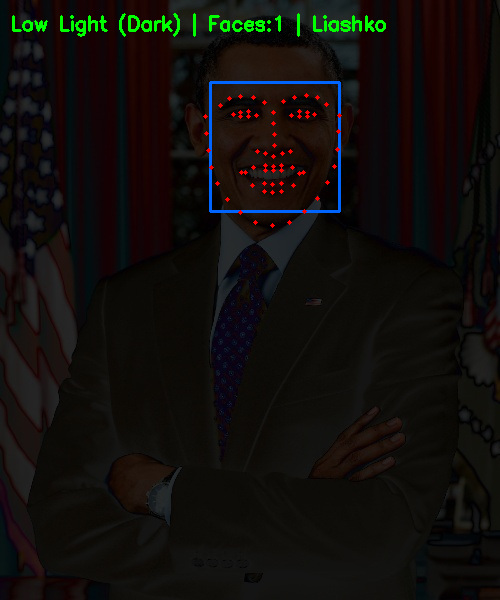


Умова 3 (Overexposed): знайдено облич — 1


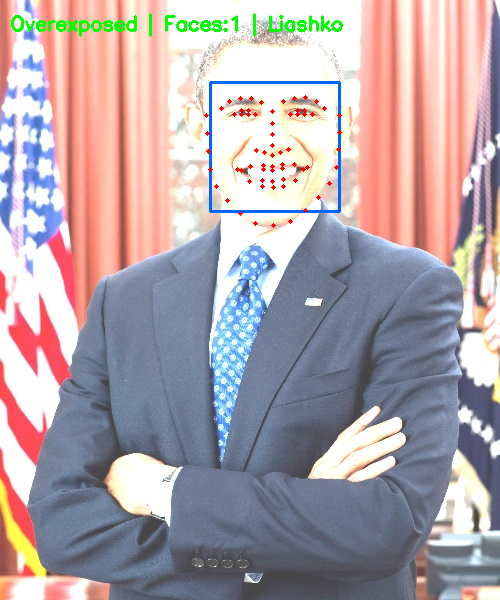


Умова 4 (Rotated 35 deg + Blur): знайдено облич — 1


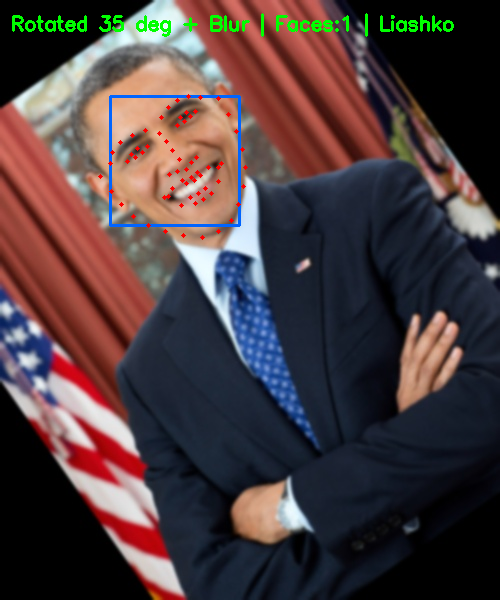

In [14]:
# Зберігаємо всі варіанти у файли (як у методичці face_images)
os.makedirs("output", exist_ok=True)
conditions = [
    ("1_normal.jpg", cond_normal, "Normal Light"),
    ("2_dark.jpg", cond_dark, "Low Light (Dark)"),
    ("3_overexposed.jpg", cond_bright, "Overexposed"),
    ("4_rotated_blur.jpg", cond_rotated, "Rotated 35 deg + Blur")
]

face_images = []
for filename, img, _ in conditions:
    cv2.imwrite(filename, img)
    face_images.append(filename)

# Ініціалізація детекторів dlib (згідно з методичкою)
detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")

# Пошук та відображення 68 особливих точок обличчя
for idx, (file, _, cond_name) in enumerate(conditions, 1):
    image = cv2.imread(file)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Детектування обличчя
    rects = detector(gray, 1)
    print(f"\nУмова {idx} ({cond_name}): знайдено облич — {len(rects)}")

    for rect in rects:
        # Відобразимо рамку детектора обличчя синім кольором
        x1, y1, x2, y2 = rect.left(), rect.top(), rect.right(), rect.bottom()
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 100, 0), 2)

        # Знаходження 68 точок для кожного знайденого обличчя
        shape = predictor(gray, rect)
        for i in range(0, 68):
            cv2.circle(image, (shape.part(i).x, shape.part(i).y), 2, (0, 0, 255), -1)

    # Підпис на зображенні
    cv2.putText(image, f"{cond_name} | Faces:{len(rects)} | Liashko", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 0), 2)

    out_path = f"./output/{os.path.split(file)[-1]}"
    cv2.imwrite(out_path, image)
    cv2_imshow(image)